# Kaggle · Evaluate: GAN vs diffusion on unseen Kerala events

The same evaluation as `04_evaluate.ipynb`, run on Kaggle so it keeps going in the background
(Save Version → Save & Run All). Settings: Accelerator **GPU T4 x2**, Internet **On**.
It downloads the tiles and both trained models from the shared Google Drive links below.
**After it finishes (~2 h):** download the whole output (Output → ⋮ → Download). Upload
`outputs/human_eval/` to Drive as `kerala_hazard_vision_ai/outputs/human_eval/` for the survey.

Two held-out Kerala events, never seen in training: one **landslide** (Pettimudi 2020) and
one **flood** (Kuttanad 2018). For each, four ways of producing the after image:

| Method | What it is |
|---|---|
| **pix2pix** (GAN) | trained on before/after pairs with slope, rain, soil, severity, hazard |
| **Conditional diffusion** | same data and inputs, Palette-style DDPM sampled with DDIM |
| **Identity** baseline | "nothing changes": after = before. Both models must beat it. |
| **Stable Diffusion img2img** | large pretrained model, no task training, text prompt only |

Metrics: SSIM, PSNR, FID (on RGB), generation time, and **severity consistency** (does the
measured damage follow the requested severity?). Plus a human real-vs-generated survey.
Every number in the report comes from `outputs/metrics.json`. Runtime: **GPU (T4)**.

In [1]:
# Shared Google Drive links ("Anyone with the link"): the tiles and both checkpoint folders.
TILES_URL = "https://drive.google.com/file/d/1WC1wOosic5MNSI44HxkPHnxxwbgibxtZ/view?usp=sharing"
GAN_FOLDER_URL = "https://drive.google.com/drive/folders/1nr4aG_OQme16UpHARmxtpOm__y6qRID3"
DIFFUSION_FOLDER_URL = "https://drive.google.com/drive/folders/1yBvYIRXWNecgHBQ7v-KDFZnLq_Et-n_I"
REPO_URL = "https://github.com/muhammedshahidsds25-collab/kerala-hazard-vision-ai.git"
REPO_DIR = "/kaggle/working/kerala-hazard-vision-ai"

!git clone -q {REPO_URL} {REPO_DIR}
%cd {REPO_DIR}
!pip install -q ".[sd]" gdown

/kaggle/working/kerala-hazard-vision-ai
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import zipfile
from pathlib import Path

import gdown

# Inputs go to /tmp: only /kaggle/working is saved as output.
gdown.download(TILES_URL, "/tmp/tiles.zip", fuzzy=True, quiet=True)
with zipfile.ZipFile("/tmp/tiles.zip") as archive:
    archive.extractall("/tmp/tiles")
for url, folder in ((GAN_FOLDER_URL, "/tmp/checkpoints"),
                    (DIFFUSION_FOLDER_URL, "/tmp/checkpoints_diffusion")):
    gdown.download_folder(url, output=folder, quiet=True)
print(sorted(p.name for p in Path("/tmp/checkpoints").iterdir()),
      sorted(p.name for p in Path("/tmp/checkpoints_diffusion").iterdir()))

['best_g.pt', 'config.json', 'history.csv', 'last.pt', 'stats.json'] ['best_ema.pt', 'config.json', 'history.csv', 'losses_diffusion.png', 'stats.json']


In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import torch

from kerala_hazard_vision_ai.config import load_config
from kerala_hazard_vision_ai.data.dataset import (
    TileDataset,
    list_tiles,
    load_shared_stats,
    to_reflectance,
    unnormalise_before,
)
from kerala_hazard_vision_ai.diffusion_baseline import load_pipeline, render_prompts, sd_img2img
from kerala_hazard_vision_ai.evaluate import (
    SEVERITY_CHANNEL,
    diffusion_predict,
    evaluate_identity,
    evaluate_model,
    evaluate_rgb,
    gan_predict,
    plot_comparison,
    plot_severity_sweep,
    rgb_uint8,
    save_metrics,
)
from kerala_hazard_vision_ai.human_eval import build_survey, save_rgb_pngs
from kerala_hazard_vision_ai.models import load_generator
from kerala_hazard_vision_ai.train_diffusion import load_diffusion

cfg = load_config("configs/default.yaml")
TILE_DIR = Path("/tmp/tiles")
OUT_DIR = Path("/kaggle/working/outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
GAN_DIR, DIFFUSION_DIR = Path("/tmp/checkpoints"), Path("/tmp/checkpoints_diffusion")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Fails loudly if the two models were trained on different tiles (e.g. after re-running 01).
stats = load_shared_stats(GAN_DIR, DIFFUSION_DIR)
test_events = [e for e in cfg.events if e.name in cfg.data.test_events]
test_sets = {e.name: TileDataset(list_tiles(TILE_DIR, [e.name]), stats, augment=False)
             for e in test_events}

generator = load_generator(GAN_DIR / "best_g.pt", cfg.model, device)
diffusion = load_diffusion(DIFFUSION_DIR / "best_ema.pt", cfg, device)
predictors = {
    "pix2pix": gan_predict(generator, device),
    "diffusion": diffusion_predict(diffusion, device, cfg.diffusion.sample_steps, cfg.train.seed),
}


def to_rgb(scaled: torch.Tensor) -> torch.Tensor:
    return rgb_uint8(to_reflectance(scaled, stats), cfg.eval.rgb_max)


def stack_tiles(ds: TileDataset, indices) -> tuple[torch.Tensor, torch.Tensor]:
    xs, ys = zip(*(ds[i] for i in indices), strict=True)
    return torch.stack(xs), torch.stack(ys)


for event in test_events:
    print(f"Test event: {event.name} ({event.hazard}), {len(test_sets[event.name])} tiles")

Test event: kuttanad_2018 (flood), 40 tiles
Test event: pettimudi_2020 (landslide), 256 tiles


## 0. Survey images first (about 10 minutes)
Builds 21 images in `outputs/human_eval/`: 7 real, 7 pix2pix, 7 diffusion, shuffled, each from
a different tile of the two test events. They come first so the Google Form can be built
while the slow evaluation below runs: open `tools/survey_form.gs` (instructions at its top),
run `createSurveyForm`, and share the link with 5–10 classmates. Do **not** share `key.csv`.

In [4]:
SURVEY_DIR = OUT_DIR / "human_eval"
pools = {"real": [], "pix2pix": [], "diffusion": []}
batch = cfg.train.batch_size
for event in test_events:
    all_x, all_y = stack_tiles(test_sets[event.name], range(len(test_sets[event.name])))
    pools["real"].append(to_rgb(all_y))
    for name, predict in predictors.items():
        pools[name].append(torch.cat(
            [to_rgb(predict(all_x[i : i + batch])) for i in range(0, len(all_x), batch)]
        ))
pngs = {name: save_rgb_pngs(torch.cat(rgb), SURVEY_DIR / "pool", name)
        for name, rgb in pools.items()}
real_pngs = pngs.pop("real")
build_survey(real_pngs, pngs, n_per_source=7, out_dir=SURVEY_DIR, seed=cfg.train.seed)
print("Survey images are ready in", SURVEY_DIR)

Survey images are ready in /kaggle/working/outputs/human_eval


## 1. pix2pix vs diffusion vs identity, per test event
The diffusion model runs 50 denoising steps per image, so this cell takes longer.

In [5]:
results = {"events": {}}
sweeps = {}
for event in test_events:
    ds = test_sets[event.name]
    scores = {"hazard": event.hazard}
    for name, predict in predictors.items():
        scores[name] = evaluate_model(predict, ds, cfg)
        sweeps[(event.name, name)] = scores[name].pop("severity_sweep")  # plotted, not tabled
    scores["identity"] = evaluate_identity(ds, cfg)
    results["events"][event.name] = scores
    display(pd.DataFrame({k: scores[k] for k in ("pix2pix", "diffusion", "identity")}).T
            .assign(event=event.name))

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 192MB/s]


,n_tiles,ssim,psnr,fid,sec_per_tile,severity_consistency,event
pix2pix,40,0.624462,17.132624,269.260162,0.007224,"{'pearson_r': 0.46387300372458024, 'mae': 0.37...",kuttanad_2018
diffusion,40,0.675086,14.801228,269.158539,3.923825,"{'pearson_r': nan, 'mae': 0.475}",kuttanad_2018
identity,40.0,0.799408,22.006252,213.785355,NaN,NaN,kuttanad_2018


,n_tiles,ssim,psnr,fid,sec_per_tile,severity_consistency,event
pix2pix,256,0.884838,30.864233,54.228302,0.00601,"{'pearson_r': 0.0341834040157831, 'mae': 0.049...",pettimudi_2020
diffusion,256,0.73996,21.351294,65.688354,3.617746,"{'pearson_r': -0.03317332363677757, 'mae': 0.0...",pettimudi_2020
identity,256.0,0.933876,32.52314,25.385635,NaN,NaN,pettimudi_2020


## 2. Figures: side by side, severity sweeps, diffusion diversity

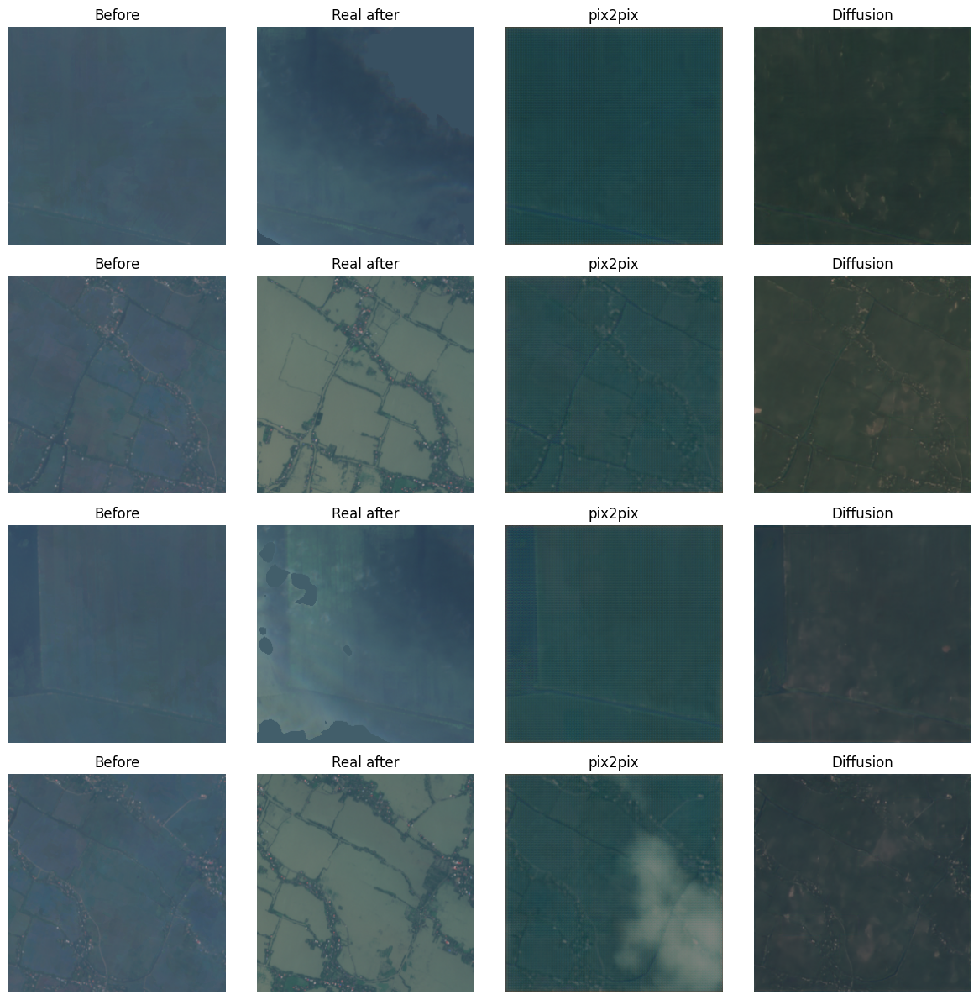

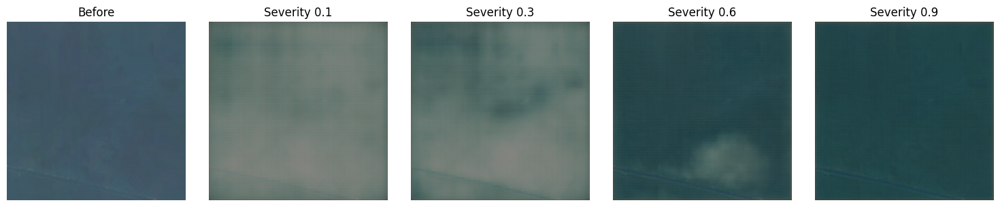

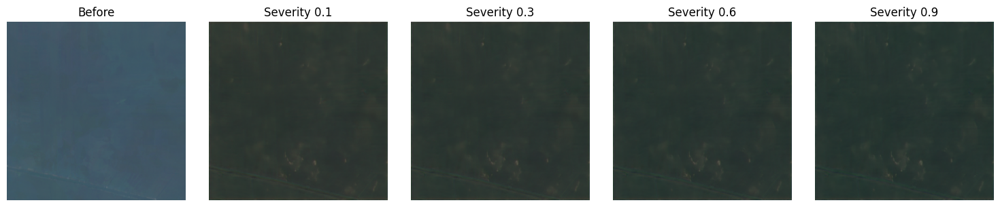

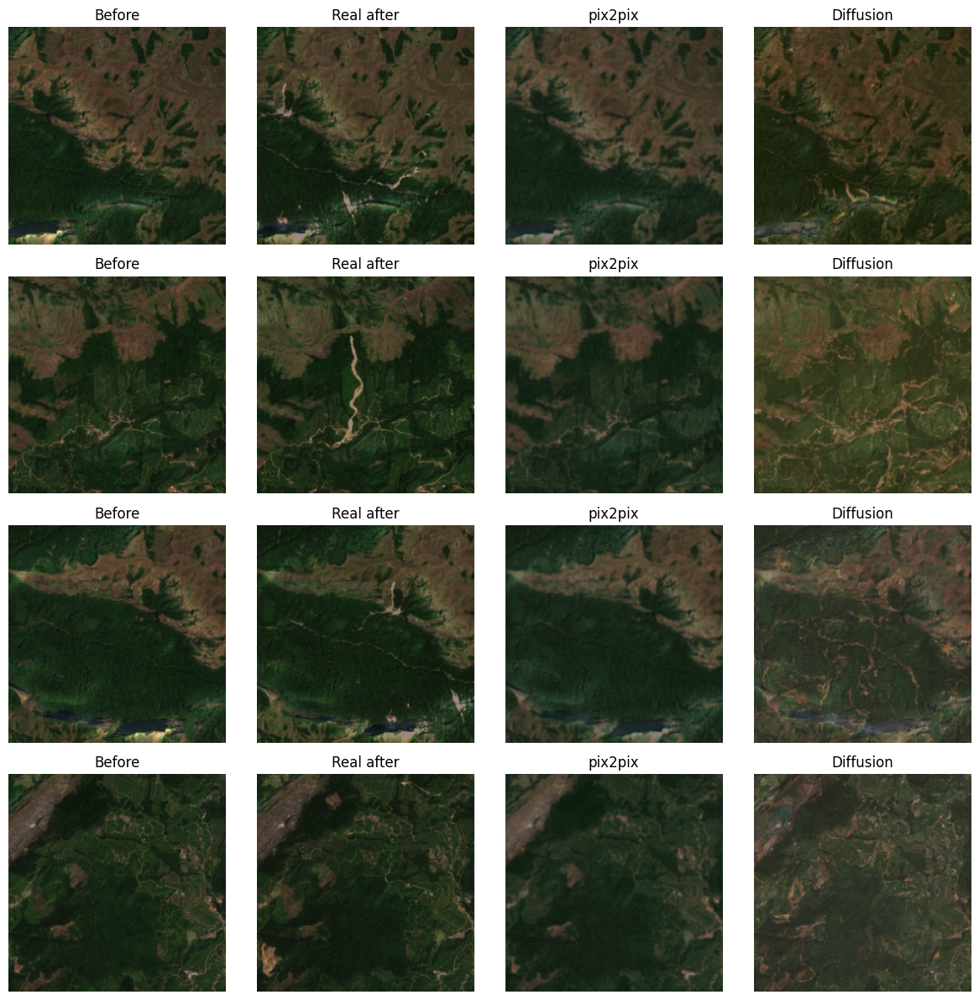

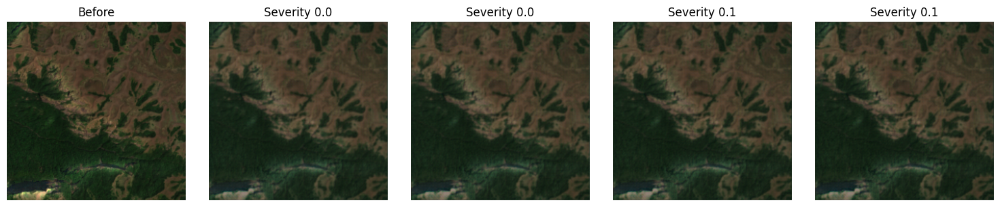

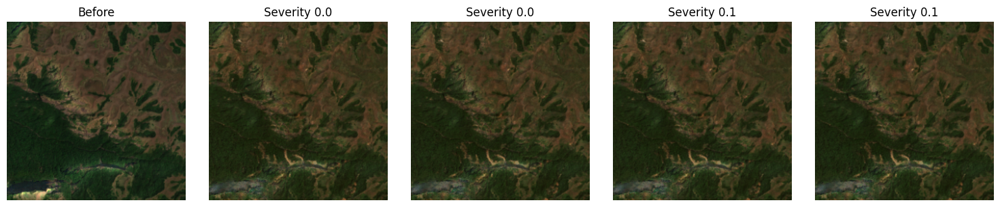

In [6]:
examples = {}
for event in test_events:
    ds = test_sets[event.name]
    severe_first = ds.severities.argsort()[::-1][:4].tolist()
    x, y = stack_tiles(ds, severe_first)
    before_rgb = rgb_uint8(unnormalise_before(x, stats), cfg.eval.rgb_max)
    examples[event.name] = (severe_first, x, before_rgb, to_rgb(y))
    display(plot_comparison(
        {"Before": before_rgb, "Real after": to_rgb(y),
         "pix2pix": to_rgb(predictors["pix2pix"](x)),
         "Diffusion": to_rgb(predictors["diffusion"](x))},
        FIG_DIR / f"comparison_{event.name}.png",
    ))
    for name, predict in predictors.items():
        frames = []
        for sev in cfg.demo.sweep[event.hazard]:
            swept = x[:1].clone()
            swept[:, SEVERITY_CHANNEL] = sev
            frames.append(to_rgb(predict(swept))[0])
        display(plot_severity_sweep(before_rgb[0], frames, cfg.demo.sweep[event.hazard],
                                    FIG_DIR / f"sweep_{event.name}_{name}.png"))

**Diversity:** diffusion can show several plausible outcomes for the same area and severity
(different random seeds). pix2pix always gives the same answer.

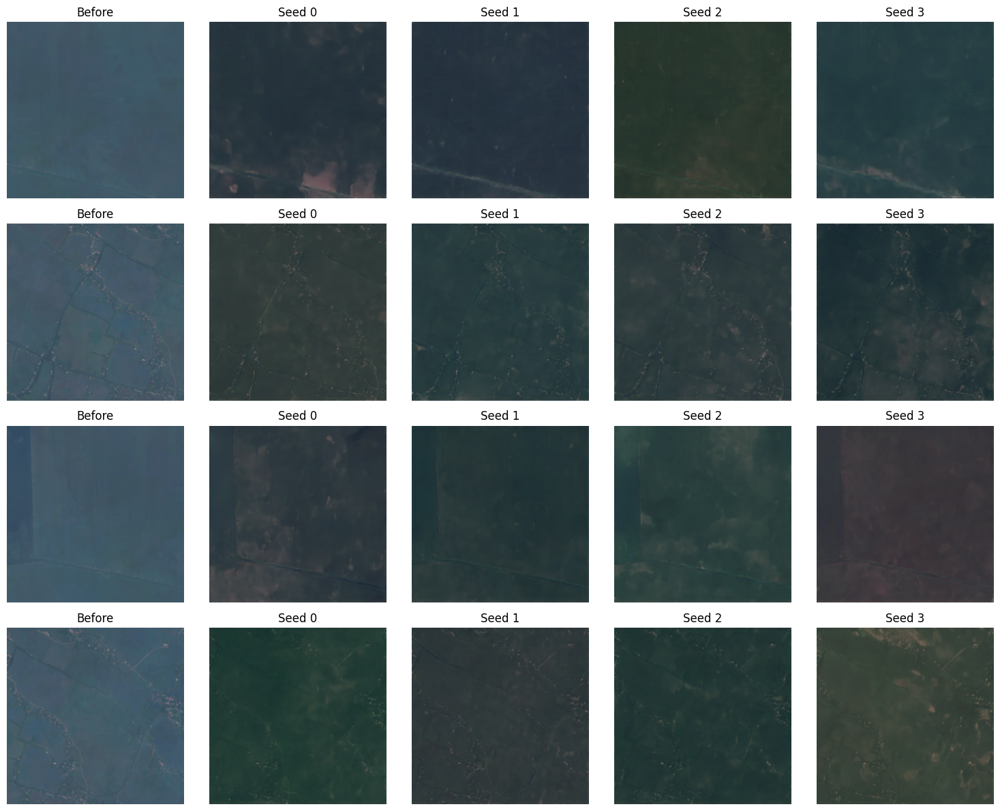

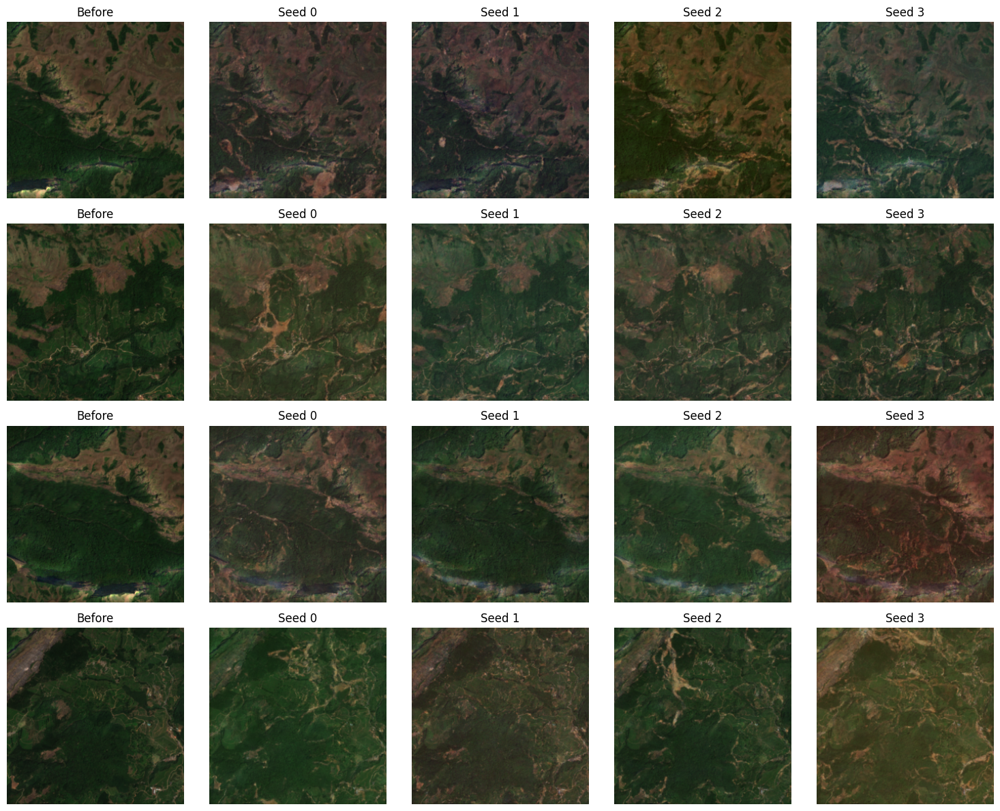

In [7]:
steps = cfg.diffusion.sample_steps
for event in test_events:
    _, x, before_rgb, _ = examples[event.name]
    samples = {f"Seed {s}": to_rgb(diffusion_predict(diffusion, device, steps, s)(x))
               for s in range(4)}
    display(plot_comparison({"Before": before_rgb, **samples},
                            FIG_DIR / f"diffusion_diversity_{event.name}.png"))

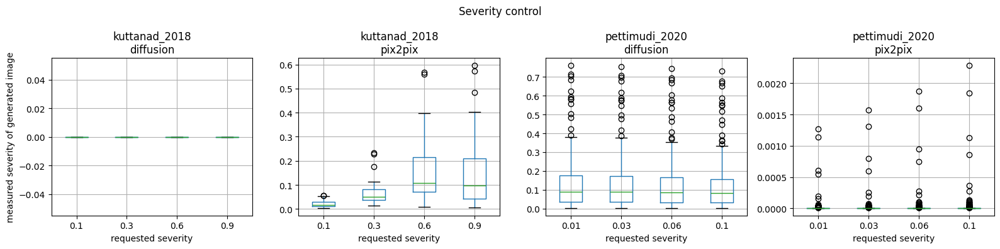

In [8]:
sweep_df = pd.concat(
    [pd.DataFrame(points).assign(event=event, model=model)
     for (event, model), points in sweeps.items()]
)
groups = sweep_df.groupby(["event", "model"])
fig, axes = plt.subplots(1, len(groups), figsize=(4 * len(groups), 4))
for ax, ((event, model), group) in zip(axes, groups, strict=True):
    group.boxplot(column="measured", by="requested", ax=ax)
    ax.set_title(f"{event}\n{model}")
    ax.set_xlabel("requested severity")
axes[0].set_ylabel("measured severity of generated image")
fig.suptitle("Severity control")
fig.tight_layout()
fig.savefig(FIG_DIR / "severity_consistency.png", dpi=150)

## 3. Stable Diffusion img2img (zero-shot, prompt engineering)
Same before images, 4 prompt designs from `configs/default.yaml`, filled in with each test
event's hazard. Takes ~20–30 min per event on a T4.

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/kerala_hazard_vision_ai/diffusion_baseline.py:77: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  outputs.append(torch.from_numpy(small).permute(2, 0, 1))


,n_tiles,ssim,psnr,fid,event
satellite image of the same area after a flood,40.0,0.622915,20.566256,260.168915,kuttanad_2018
"Sentinel-2 satellite photo, top-down view, after a flood, same terrain and rivers",40.0,0.628076,20.579245,254.667282,kuttanad_2018
"aerial view after a severe flood, exposed brown soil, destroyed vegetation, debris",40.0,0.662330,20.698866,320.235504,kuttanad_2018
"post-disaster satellite imagery, flood, realistic, high detail",40.0,0.615881,20.517260,291.801025,kuttanad_2018


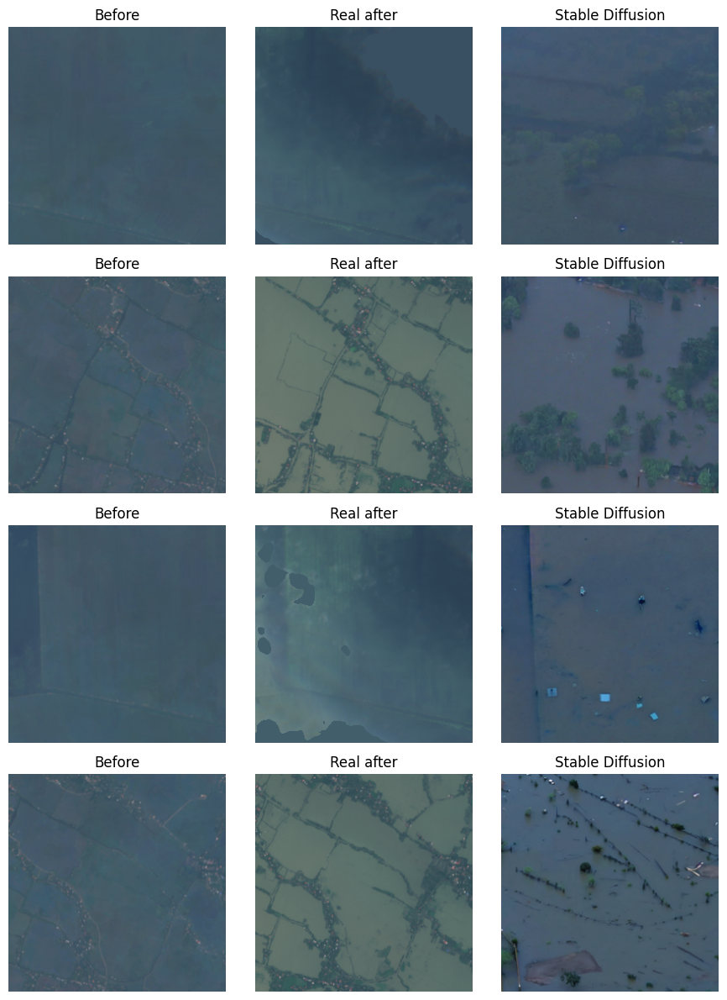

,n_tiles,ssim,psnr,fid,event
satellite image of the same area after a landslide,256.0,0.525429,23.592995,133.986786,pettimudi_2020
"Sentinel-2 satellite photo, top-down view, after a landslide, same terrain and rivers",256.0,0.531714,23.741083,162.488327,pettimudi_2020
"aerial view after a severe landslide, exposed brown soil, destroyed vegetation, debris",256.0,0.548677,23.974159,195.353088,pettimudi_2020
"post-disaster satellite imagery, landslide, realistic, high detail",256.0,0.519735,23.484890,132.094772,pettimudi_2020


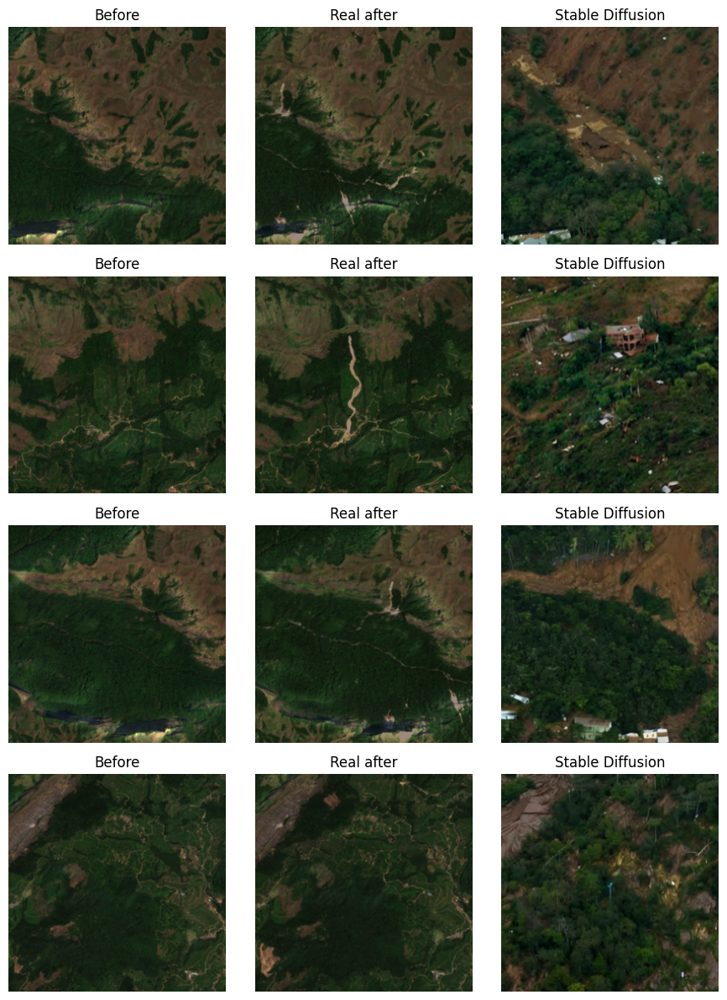

In [9]:
pipe = load_pipeline(cfg.eval, device)
for event in test_events:
    ds = test_sets[event.name]
    severe_first, _, before_rgb, real_rgb = examples[event.name]
    all_x, all_y = stack_tiles(ds, range(len(ds)))
    test_before_rgb = rgb_uint8(unnormalise_before(all_x, stats), cfg.eval.rgb_max)
    test_real_rgb = to_rgb(all_y)

    sd_scores, sd_examples = {}, {}
    for prompt in render_prompts(cfg.eval.prompts, event.hazard):
        sd_rgb = sd_img2img(pipe, test_before_rgb, prompt, cfg.eval, seed=cfg.train.seed)
        sd_scores[prompt] = evaluate_rgb(sd_rgb, test_real_rgb)
        sd_examples[prompt] = sd_rgb[severe_first]
    # Chosen on the test set: this favours the baseline, which only makes our models' win harder.
    best_prompt = max(sd_scores, key=lambda p: sd_scores[p]["ssim"])
    results["events"][event.name]["stable_diffusion"] = sd_scores
    results["events"][event.name]["stable_diffusion_best_prompt"] = best_prompt
    display(pd.DataFrame(sd_scores).T.assign(event=event.name))
    display(plot_comparison(
        {"Before": before_rgb, "Real after": real_rgb,
         "Stable Diffusion": sd_examples[best_prompt]},
        FIG_DIR / f"comparison_stable_diffusion_{event.name}.png",
    ))
del pipe
torch.cuda.empty_cache()

## 4. Results table → `outputs/metrics.json`

In [10]:
save_metrics(results, OUT_DIR / "metrics.json")
rows = []
for event_name, scores in results["events"].items():
    methods = {
        "pix2pix (GAN)": scores["pix2pix"],
        "Conditional diffusion": scores["diffusion"],
        "Identity baseline": scores["identity"],
        "Stable Diffusion (best prompt)":
            scores["stable_diffusion"][scores["stable_diffusion_best_prompt"]],
    }
    for method, metrics in methods.items():
        rows.append({"event": event_name, "hazard": scores["hazard"], "method": method, **metrics})
table = pd.DataFrame(rows)
table[["event", "hazard", "method", "n_tiles", "ssim", "psnr", "fid", "sec_per_tile"]].round(3)

,event,hazard,method,n_tiles,ssim,psnr,fid,sec_per_tile
0,kuttanad_2018,flood,pix2pix (GAN),40,0.624,17.133,269.260,0.007
1,kuttanad_2018,flood,Conditional diffusion,40,0.675,14.801,269.159,3.924
2,kuttanad_2018,flood,Identity baseline,40,0.799,22.006,213.785,NaN
3,kuttanad_2018,flood,Stable Diffusion (best prompt),40,0.662,20.699,320.236,NaN
4,pettimudi_2020,landslide,pix2pix (GAN),256,0.885,30.864,54.228,0.006
5,pettimudi_2020,landslide,Conditional diffusion,256,0.740,21.351,65.688,3.618
6,pettimudi_2020,landslide,Identity baseline,256,0.934,32.523,25.386,NaN
7,pettimudi_2020,landslide,Stable Diffusion (best prompt),256,0.549,23.974,195.353,NaN


Done. Download the output and upload `outputs/human_eval/` to Google Drive for the survey form.
The survey answers are scored afterwards from `answers.csv` with `human_eval.score_survey`.